# 10 床下を介した多室暖房

床下→LDK／寝室へ暖気を分配する構成の教材用縮約モデル。原住宅の再現計算ではない。

## 到達目標
各室の給排気を釣り合わせる。地盤15℃は固定境界であり、旧版の応答係数地盤モデルとは異なる。

## 実行環境
Python 3.10以上とvtsimnx engineが必要です。Colabのlocalhostは手元PCのサーバーを指しません。次の設定セルのAPI URLを到達可能なものに変更します。APIキーは環境変数で渡し、ノートに保存しません。

検証engine commit: `5eeffb2f8012a2fe41bca705450b0dd0a952326d`。入力モデルは実計算確認済ですが、原住宅の年間再現とは範囲が異なります。

## 実行版の使い方
このノートは検証対象のvtsimnx commit 5eeffb2f8012a2fe41bca705450b0dd0a952326d に合わせた代表教材です。上から順に実行します。
Pythonクライアントの導入だけではengineは起動しません。教材17以外は接続可能なengineと、必要に応じてVTSIMNX_API_KEYが必要です。Colabの127.0.0.1は手元PCのengineを指しません。
入力はノート内に含めています。元のDriveパスや測定CSVを別途読む必要はありません。
出力は教材フォルダ内のresults/10/に保存します。詳しい準備は同じフォルダの00_実行ガイド.ipynbを参照してください。


In [1]:
import os, sys, subprocess
# 検証runnerのみ専用環境で導入済みの依存を再利用する。通常はこのセルで導入する。
if os.environ.get("VTSIMNX_TUTORIAL_SKIP_INSTALL") != "1":
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--upgrade", "pip", "setuptools>=68,<81", "wheel"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
        "vtsimnx @ git+https://github.com/iguchi-lab/vtsimnx@5eeffb2f8012a2fe41bca705450b0dd0a952326d",
        "matplotlib", "japanize-matplotlib"])


In [2]:
import os, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import japanize_matplotlib
from IPython.display import display
import vtsimnx as vt

# ローカルJupyterでは、ノートブックと同じフォルダを作業フォルダにする。
DATA_DIR = Path(os.environ.get("VTSIMNX_TUTORIAL_DATA", ".")).expanduser().resolve()
BASE_URL = os.environ.get("VTSIMNX_API_URL", "http://127.0.0.1:8000")
API_KEY = os.environ.get("VTSIMNX_API_KEY")
OUTPUT = DATA_DIR / "results" / "10"
OUTPUT.mkdir(parents=True, exist_ok=True)


## 入力を読む
次の辞書はvtsimnxのネイティブ形式です。風量はm³/s、熱量はW、熱容量はJ/Kです。

In [3]:
configs = {'10_floor_rooms': {'builder': {},
                    'simulation': {'index': {'start': '2026-01-01T00:00:00',
                                             'end': '2026-01-02T23:00:00',
                                             'length': 48,
                                             'timestep': 3600}},
                    'nodes': [{'key': 'outside', 't': 5},
                              {'key': 'supply', 't': 35},
                              {'key': 'ground', 't': 15},
                              {'key': 'underfloor',
                               't': 20,
                               'v': 40,
                               'calc_t': True,
                               'thermal_mass': 2000000.0},
                              {'key': 'LDK', 't': 20, 'v': 80, 'calc_t': True, 'thermal_mass': 3000000.0},
                              {'key': 'bedroom',
                               't': 20,
                               'v': 40,
                               'calc_t': True,
                               'thermal_mass': 1000000.0}],
                    'ventilation_branches': [{'key': 'supply->underfloor',
                                              'source': 'supply',
                                              'target': 'underfloor',
                                              'vol': 0.08333333333333333},
                                             {'key': 'underfloor->LDK',
                                              'source': 'underfloor',
                                              'target': 'LDK',
                                              'vol': 0.05555555555555555},
                                             {'key': 'underfloor->bedroom',
                                              'source': 'underfloor',
                                              'target': 'bedroom',
                                              'vol': 0.027777777777777776},
                                             {'key': 'LDK->outside',
                                              'source': 'LDK',
                                              'target': 'outside',
                                              'vol': 0.05555555555555555},
                                             {'key': 'bedroom->outside',
                                              'source': 'bedroom',
                                              'target': 'outside',
                                              'vol': 0.027777777777777776}],
                    'thermal_branches': [{'key': 'underfloor->ground',
                                          'source': 'underfloor',
                                          'target': 'ground',
                                          'conductance': 50},
                                         {'key': 'underfloor->LDK',
                                          'source': 'underfloor',
                                          'target': 'LDK',
                                          'conductance': 60},
                                         {'key': 'underfloor->bedroom',
                                          'source': 'underfloor',
                                          'target': 'bedroom',
                                          'conductance': 30},
                                         {'key': 'outside->LDK',
                                          'source': 'outside',
                                          'target': 'LDK',
                                          'conductance': 80},
                                         {'key': 'outside->bedroom',
                                          'source': 'outside',
                                          'target': 'bedroom',
                                          'conductance': 40}]}}


## 実行と結果の取得
計算ごとの要求JSONを保存し、必要な系列をDataFrameとして取得します。

In [4]:
results = {}
for name, config in configs.items():
    results[name] = vt.run_calc(BASE_URL, config, api_key=API_KEY,
        as_result=True, raise_on_error=True, timeout=1800, request_output_path=OUTPUT / (name + "_request.json"))
    print(name, results[name].artifact_dir)


10_floor_rooms artifacts.1794699413111.output.88acd5a75a4c4add9bf8e3fd4e84138e


10_floor_rooms


,LDK,bedroom,ground,outside,supply,underfloor
time,,,,,,
2026-01-01 00:00:00,19.024630,18.669361,15.0,5.0,35.0,21.457703
2026-01-01 01:00:00,18.357735,17.856018,15.0,5.0,35.0,22.393980
2026-01-01 02:00:00,17.896852,17.363489,15.0,5.0,35.0,22.994019
2026-01-01 03:00:00,17.574511,17.068558,15.0,5.0,35.0,23.377319
2026-01-01 04:00:00,17.346087,16.894306,15.0,5.0,35.0,23.621004


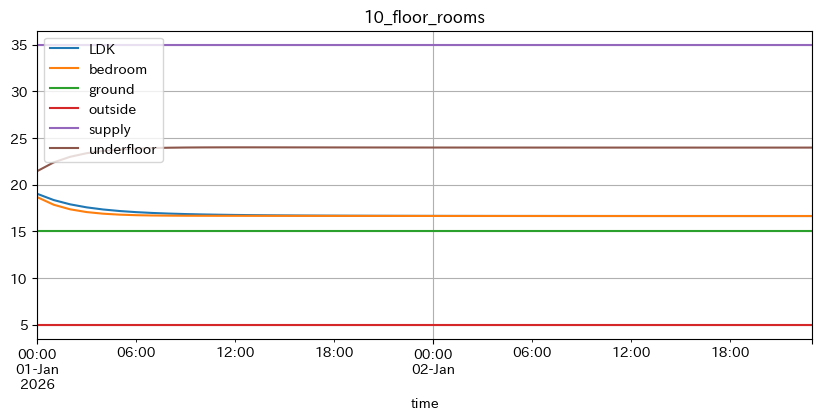

In [5]:
frames = {name: result.get_series_df('thermal_temperature', raise_on_error=True) for name, result in results.items()}
for name, frame in frames.items():
    print(name)
    display(frame.head())
    frame.to_csv(OUTPUT / (name + "_thermal_temperature.csv"), encoding="utf-8-sig")
    frame.plot(title=name, figsize=(10, 4), grid=True)


## 確認・発展
分配風量比と地盤コンダクタンスを変え、床下・室温を比較する。

保存された時刻の値は当該ステップ更新後の値です。初期値との比較ではこの差に注意します。

## 原典との対応
- S013 三木　シュミレーション のコピー
- S014 三木　シュミレーション のコピー
- S015 東大阪地点　いちと のコピー
- S029 240630_higashiosaka.ipynb
- S030 250111_東大阪2024_data整理.ipynb
- S031 250111_東大阪2024分析_r2.ipynb
- S032 250111_東大阪2024分析_r2.ipynb のコピー
- S033 250114_東大阪2024分析_r2.ipynb
- S039 東大阪地点　いちと のコピー
- S043 220225_東大阪.ipynb
- S044 220228_東大阪.ipynb
- S045 220301_1700_東大阪calc.ipynb

S番号は原典調査時の識別子です。原典の完全な台帳は管理者のDrive整理資料に保管しています。